In [225]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

emploi = pd.read_csv("DS_RP_EMPLOI_LR_COMP_2023_data.csv",sep=";",dtype={"GEO": str,"EMPSTA_ENQ":str})
emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO_OBJECT','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["GEO_OBJECT"] == "DEP"]
emploi_dep = emploi_dep.loc[emploi_dep["PCS"] == "_T"]
emploi_dep = emploi_dep.loc[emploi_dep["TIME_PERIOD"] == 2023]

dep_aca = pd.read_csv("correspondance dep-aca.csv",sep=";")
dep_aca.head()

emploi_aca= emploi_dep.merge(
  dep_aca,
  left_on = ["GEO"],
  right_on = ["Departement"],
  how = "left"
)

emploi_aca= emploi_aca.groupby(["Academie","EMPSTA_ENQ"]).agg({"OBS_VALUE":"sum"}).reset_index()

emploi_aca = emploi_aca.pivot(index="Academie", columns="EMPSTA_ENQ", values="OBS_VALUE")
emploi_aca.head()


EMPSTA_ENQ,1,1T2,2
Academie,,,
AIX-MARSEILLE,1.177153e+06,1.305135e+06,127981.49948
AMIENS,7.694747e+05,8.656820e+05,96207.34067
BESANCON,4.898079e+05,5.373487e+05,47540.77472
BORDEAUX,1.500369e+06,1.652503e+06,152134.02862
CLERMONT-FERRAND,5.549894e+05,6.058450e+05,50855.58758


Le jeu provient de : https://www.data.gouv.fr/datasets/population-active-et-chomage-principaux-indicateurs-dossier-complet-1

In [ ]:
emploi_aca["Taux d'activité"]=emploi_aca["1"]/emploi_aca['1T2']

emploi_aca= emploi_aca.drop(columns=["1","2"])
emploi_aca=emploi_aca.reset_index()

emploi_aca.columns.tolist()

emploi_aca=emploi_aca.rename(columns = {"1T2":"Population active"})
emploi_aca.head()


EMPSTA_ENQ,Academie,Population active,Taux d'activité
0,AIX-MARSEILLE,1.305135e+06,0.901940
1,AMIENS,8.656820e+05,0.888865
2,BESANCON,5.373487e+05,0.911527
3,BORDEAUX,1.652503e+06,0.907937
4,CLERMONT-FERRAND,6.058450e+05,0.916058


In [209]:
emploi_aca.sort_values(by="Taux d'activité").head(20)

EMPSTA_ENQ,Academie,Population active,Taux d'activité
11,LA REUNION,3.760340e+05,0.787271
9,GUADELOUPE,1.573689e+05,0.820405
15,MARTINIQUE,1.526611e+05,0.856454
10,GUYANE,9.207165e+04,0.860825
16,MONTPELLIER,1.258952e+06,0.872688
12,LILLE,1.818526e+06,0.883779
1,AMIENS,8.656820e+05,0.888865
24,REIMS,5.831576e+05,0.893580
6,CRETEIL,2.216634e+06,0.899419
0,AIX-MARSEILLE,1.305135e+06,0.901940


Les données de bac proviennent de : https://www.data.gouv.fr/datasets/le-baccalaureat-par-academie

In [210]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

bac = pd.read_csv("fr-en-baccalaureat-par-academie.csv",sep=";")
bac = bac.loc[bac["Voie"] == "BAC GENERAL"]

bac["Sexe"]= bac["Sexe"].replace("MASCULIN", "GARCONS")
bac["Sexe"]= bac["Sexe"].replace("FEMININ", "FILLES")
bac.head(5)

bac_aca=bac.groupby("Libellé académie").agg({"Nombre d'inscrits": 'sum',"Nombre de présents":"sum","Nombre d'admis totaux": 'sum',
                                             "Nombre de refusés totaux":"sum",
                                             "Nombre d'admis avec mention TB avec les félicitations du jury":"sum",
                                             "Nombre d'admis avec mention TB sans les félicitations du jury":"sum"})


bac_aca ["Nombre d'admis avec mention TB"] = bac_aca ["Nombre d'admis avec mention TB avec les félicitations du jury"]+bac_aca ["Nombre d'admis avec mention TB sans les félicitations du jury"]
bac_aca=bac_aca.drop(columns=["Nombre d'admis avec mention TB avec les félicitations du jury","Nombre d'admis avec mention TB sans les félicitations du jury"])
bac_aca.head(30)

,Nombre d'inscrits,Nombre de présents,Nombre d'admis totaux,Nombre de refusés totaux,Nombre d'admis avec mention TB
Libellé académie,,,,,
AIX-MARSEILLE,86023,85603,82816,2787,13366
AMIENS,50715,50594,48330,2264,6721
BESANCON,29763,29710,28626,1084,3514
BORDEAUX,95071,94698,91467,3231,11579
CLERMONT-FERRAND,33315,33239,32146,1093,4090
CORSE,7768,7752,7554,198,1191
CRETEIL,137837,137020,128434,8586,13493
DIJON,40950,40853,39450,1403,4905
GRENOBLE,97721,97546,94794,2752,14381


In [211]:
bac_emploi= bac_aca.merge(
  emploi_aca,
  left_on = ["Libellé académie"],
  right_on = ["Academie"],
  how = "left"
)
bac_emploi["taux de réussite"]=bac_emploi["Nombre d'admis totaux"]/bac_emploi["Nombre de présents"]

bac_emploi.sort_values("taux de réussite")


,Nombre d'inscrits,Nombre de présents,Nombre d'admis totaux,Nombre de refusés totaux,Nombre d'admis avec mention TB,Academie,Population active,Taux d'activité,taux de réussite
16,11939,11816,9372,2444,408,NaN,NaN,NaN,0.793162
10,8132,8113,7144,969,553,GUYANE,9.207165e+04,0.860825,0.880562
6,137837,137020,128434,8586,13493,CRETEIL,2.216634e+06,0.899419,0.937338
9,13904,13885,13195,690,1417,GUADELOUPE,1.573689e+05,0.820405,0.950306
25,33452,33368,31795,1573,3830,REIMS,5.831576e+05,0.893580,0.952859
20,61017,60932,58183,2749,8928,NICE,9.845448e+05,0.903905,0.954884
1,50715,50594,48330,2264,6721,AMIENS,8.656820e+05,0.888865,0.955252
29,207275,206263,197042,9221,28630,VERSAILLES,2.840825e+06,0.915211,0.955295
14,96638,96218,92404,3814,12363,LYON,1.596500e+06,0.912833,0.960361
21,88280,88076,84680,3396,11222,NORMANDIE,1.491831e+06,NaN,0.961442


Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par académie - 2023")

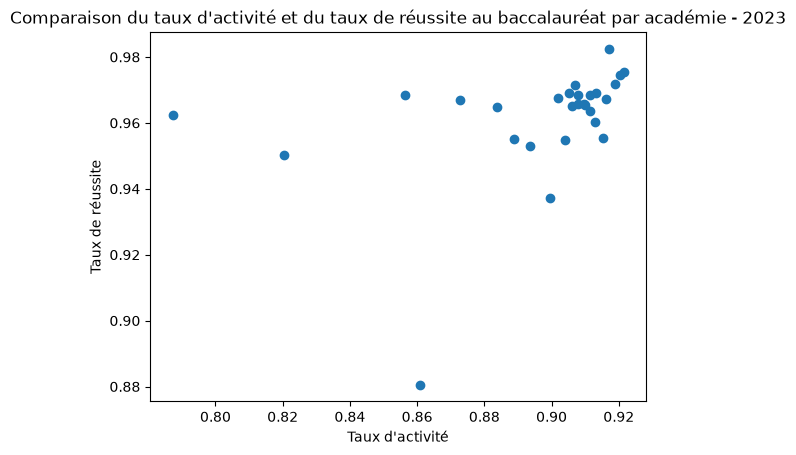

In [212]:
plt.scatter(bac_emploi["Taux d'activité"],bac_emploi["taux de réussite"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par académie - 2023")

Le résultat n'est pas très concluant. 
On a envie de conclure à une corrélation positive mais il n'y aurait pas d'homoscédasticité des résidus : sur les faibles valeurs de taux d'activité, l'écart à la tendance serait bien plus élevé que sur les fortes valeurs.
On tente de supprimer les valeurs extrêmes (qui sont probablement les outre mer) pour se concentrer sur le nuage de points à droite.

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par académie - France métropolitaine 2023")

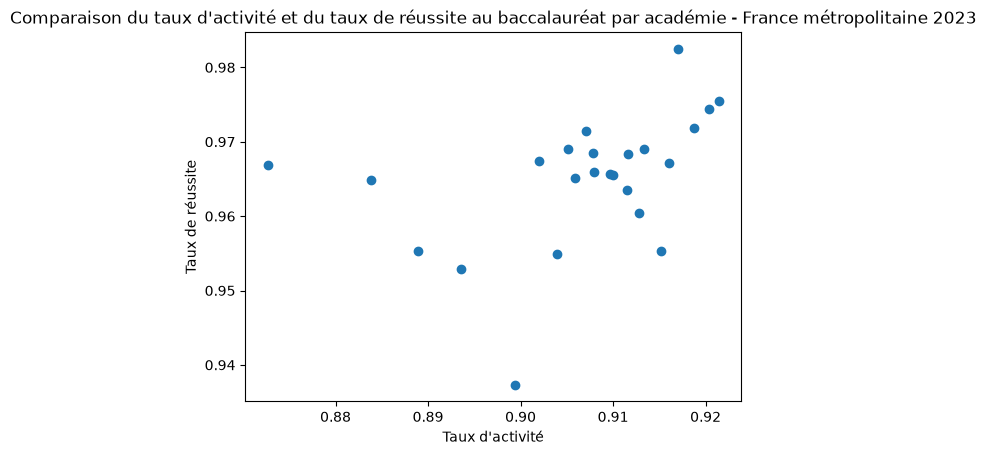

In [213]:
bac_emploi_metropole = bac_emploi[~bac_emploi["Academie"].isin(["LA REUNION","GUADELOUPE","MARTINIQUE","GUYANE"])]

plt.scatter(bac_emploi_metropole["Taux d'activité"],bac_emploi_metropole["taux de réussite"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par académie - France métropolitaine 2023")

La corrélation semble meilleure en se limitant à la France métropolitaine.

On teste de comparer le taux d'activité au nombre de mentions TB.

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions TB au baccalauréat par académie - 2023")

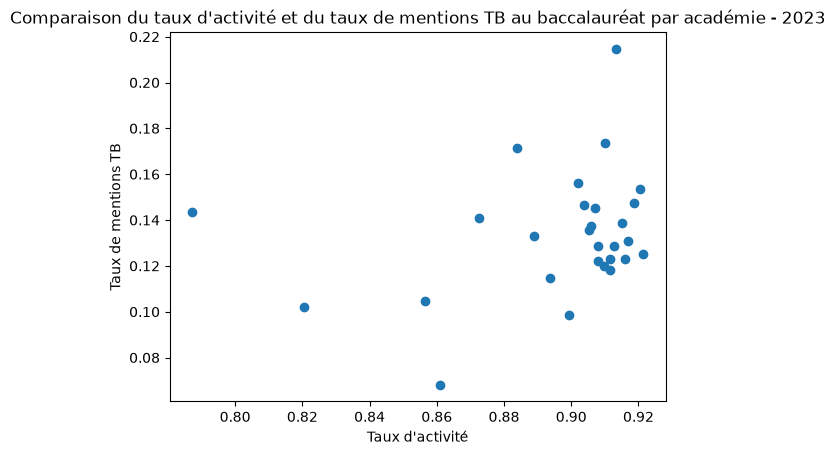

In [214]:
bac_emploi["Taux de mentions TB"] = bac_emploi["Nombre d'admis avec mention TB"]/bac_emploi["Nombre de présents"]

bac_emploi.head()

plt.scatter(bac_emploi["Taux d'activité"],bac_emploi["Taux de mentions TB"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de mentions TB")
plt.title("Comparaison du taux d'activité et du taux de mentions TB au baccalauréat par académie - 2023")

La corrélation ne semble pas évidente. 
On se penche désormais sur les données d'inscrits au RSA, également présentes sur le site data.gouv.
On le nettoie pour garder les données intéressantes et le rendre plus facile à manipuler. On reprend l'année 2023, on prend le 1er janvier arbitrairement.

In [215]:
rsa= pd.read_csv("rsa_ppa_s_agg_age_5_dep.csv",sep=";")

rsa=rsa[rsa["Date référence"]=="2023-01-01"]

rsa= rsa.drop(columns=["Nom département","Numéro région","Nom région","Lieu résidence","Date référence"])

rsa =rsa.groupby(["Numéro département","RSA ou PPA"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                                           "Nombre personnes RSA_PPA":"sum"})
rsa = rsa.reset_index()

rsa= rsa[rsa["RSA ou PPA"].isin(["RSA et PA","RSA seul"])]

rsa_aca= rsa.merge(
  dep_aca,
  left_on = ["Numéro département"],
  right_on = ["Departement"],
  how = "left"
)

rsa_aca =rsa_aca.groupby(["Academie"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                            "Nombre personnes RSA_PPA":"sum"})
rsa_aca=rsa_aca.reset_index()
rsa_aca.head()

,Academie,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA
0,AIX-MARSEILLE,91871,199085
1,AMIENS,54806,117353
2,BESANCON,23593,49205
3,BORDEAUX,85355,166902
4,CLERMONT-FERRAND,29315,60089


Pour obtenir un taux afin d'augmenter la comparabilité entre des académie de population différente, on rapproche ces données du fichier emploi, où on avait la donnée de population active.

In [216]:
rsa_bac= rsa_aca.merge(
     bac_emploi,
  left_on = ["Academie"],
  right_on = ["Academie"],
  how = "left" 
)

rsa_bac ["Nombre personnes bénéficiant du RSA par actif"]=rsa_bac["Nombre personnes RSA_PPA"]/rsa_bac["Population active"]
rsa_bac.head(30)

,Academie,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Nombre d'inscrits,Nombre de présents,Nombre d'admis totaux,Nombre de refusés totaux,Nombre d'admis avec mention TB,Population active,Taux d'activité,taux de réussite,Taux de mentions TB,Nombre personnes bénéficiant du RSA par actif
0,AIX-MARSEILLE,91871,199085,86023.0,85603.0,82816.0,2787.0,13366.0,1.305135e+06,0.901940,0.967443,0.156139,0.152540
1,AMIENS,54806,117353,50715.0,50594.0,48330.0,2264.0,6721.0,8.656820e+05,0.888865,0.955252,0.132842,0.135561
2,BESANCON,23593,49205,29763.0,29710.0,28626.0,1084.0,3514.0,5.373487e+05,0.911527,0.963514,0.118277,0.091570
3,BORDEAUX,85355,166902,95071.0,94698.0,91467.0,3231.0,11579.0,1.652503e+06,0.907937,0.965881,0.122273,0.100999
4,CLERMONT-FERRAND,29315,60089,33315.0,33239.0,32146.0,1093.0,4090.0,6.058450e+05,0.916058,0.967117,0.123048,0.099182
5,CORSE,9248,16351,7768.0,7752.0,7554.0,198.0,1191.0,1.546046e+05,0.920397,0.974458,0.153638,0.105760
6,CRETEIL,159343,327653,137837.0,137020.0,128434.0,8586.0,13493.0,2.216634e+06,0.899419,0.937338,0.098475,0.147816
7,DIJON,33567,68783,40950.0,40853.0,39450.0,1403.0,4905.0,7.142098e+05,0.909682,0.965657,0.120065,0.096306
8,GRENOBLE,52750,106000,97721.0,97546.0,94794.0,2752.0,14381.0,1.662348e+06,0.918724,0.971788,0.147428,0.063765
9,GUADELOUPE,40384,73923,13904.0,13885.0,13195.0,690.0,1417.0,1.573689e+05,0.820405,0.950306,0.102053,0.469743


Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions TB au baccalauréat par académie - 2023")

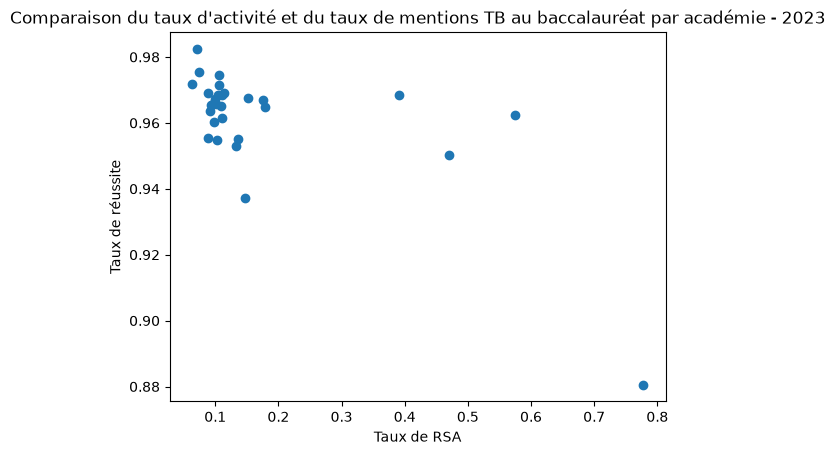

In [217]:
plt.scatter(rsa_bac["Nombre personnes bénéficiant du RSA par actif"],rsa_bac["taux de réussite"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de mentions TB au baccalauréat par académie - 2023")